# Limpieza de datos — *La música y su influencia en el estado de ánimo*

Notebook interactivo para explorar, limpiar y analizar las respuestas del formulario.


In [45]:
import re, unicodedata
from difflib import SequenceMatcher
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualización
pd.set_option('display.max_colwidth', 70)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)
sns.set_theme(style='whitegrid')

# --- Rutas ---------------------------------------------------------------
NOMBRE_CSV = 'La_música_y_su_influencia_en_el_estado_de_ánimo__respuestas__-_Respuestas_de_formulario_1.csv'
RAW_CSV = next((p / NOMBRE_CSV for p in [Path('.'), Path('data/raw'), Path('/mnt/user-data/uploads')]
                if (p / NOMBRE_CSV).exists()), Path(NOMBRE_CSV))
PROCESSED_CSV = Path('data/processed/datos_limpios_musica.csv')

# Si es True, las respuestas marcadas como posible copia se incluyen en los análisis
INCLUIR_POSIBLES_COPIAS = False

## 1. Cargar datos crudos

In [46]:
import pandas as pd
from pathlib import Path

# Corregimos el nombre usando el texto real con tildes, tal como existe en el sistema de archivos de Colab
NOMBRE_REAL_CSV = 'La música y su influencia en el estado de ánimo (respuestas) - Respuestas de formulario 1.csv'

# Buscar el archivo en las rutas habituales
RAW_CSV = next((p / NOMBRE_REAL_CSV for p in [Path('.'), Path('data/raw'), Path('/mnt/user-data/uploads')]
                if (p / NOMBRE_REAL_CSV).exists()), Path(NOMBRE_REAL_CSV))

df = pd.read_csv(RAW_CSV)
print(f"Shape original: {df.shape}")
df.head(3)

Shape original: (24, 18)


,Marca temporal,Número de cuenta,1. ¿Qué tipo de música escuchas con mayor frecuencia y por qué?,2. ¿Cuánto tiempo al día dedicas aproximadamente a escuchar música?,3. ¿En qué momentos del día acostumbras escuchar música y qué actividades realizas mientras la escuchas?,"4. ¿Qué plataformas, aplicaciones o dispositivos utilizas para escuchar música?",5. ¿Cómo describirías tu estado de ánimo antes y después de escuchar tu música favorita?,"6. ¿Qué géneros musicales te hacen sentir feliz, tranquilo, triste o motivado?",7. ¿Puedes describir una experiencia en la que una canción haya cambiado tu estado de ánimo?,"8. ¿Qué tipo de música escuchas cuando te sientes triste, estresado o preocupado, y por qué?",9. ¿Cómo influye la música en tu nivel de energía y motivación durante el día?,"10. ¿De qué manera influye la música en tu concentración al estudiar, trabajar o realizar tareas?",11. ¿Cómo describirías la influencia de la música en tu descanso o calidad del sueño?,12. ¿Qué diferencias notas entre realizar una actividad con música y realizarla en silencio?,"13. ¿Qué características de una canción, como el ritmo, la letra o el volumen, influyen más en tus emociones?",14. ¿Consideras que la música puede ayudar a manejar emociones negativas? Explica tu respuesta con un ejemplo.,15. ¿Cómo describirías la importancia de la música en tu vida y en tu bienestar emocional?,16. ¿Cuáles son los 5 artistas musicales que escuchas con mayor frecuencia
0,29/10/2026 22:28:00,422085764,Electrónica porque me relaja,4 horas,Al momento de realizar las tareas o estando en un espacio de relaj...,YouTube,Normal y después con la música me siento bien,"Electrónica, Pop, Banda y Salsa",No tengo,Electrónica para relajar,Me mantiene motivado y alegre todo el día,Me puedo concentrar más,Me relaja,El ambiente cambia con el ritmo de la música se siente más vivo el...,El ritmo o la letra,"Si, ya que te ayuda a identificarte con la canción y poder sentirs...",Necesaria para tener una motivación,"Alan walker, Ana Mena, Morat, Melendi y \nsangiovanni"
1,30/10/2026 18:02:55,321188065,No escucho música,0,NaN,No escucho,Es igual,Ninguno,"No, me es indistinto","Si antes no escuchaba, estresado menos",No influye,Distrae al estudiar o al hacer cosas que impliquen concentración,No afecta,"Con música me distraigo más rápido y me estreso más rápido, no dej...",El volumen y el idioma,Podría si la persona está acostumbrada a escuchar música y asocia ...,"No es importante, fácilmente no podría existir y sería lo mismo, s...",1. Morat\n2. Ariana Grande\n3. Daniel Rosenfeld\nDel resto no cono...
2,30/10/2026 18:36:42,424059594,Corridos porque el me gusta el ritmo,7 horas,"Al ir y regresar de mi casa a la escuela, al hacer ejercicio y cua...",Spotify,Mejora ya que me relaja,"Corridos, reggaeton y banda",Cuando estoy haciendo ejercicio y sale una canción con un ritmo rá...,"Baladas, banda o corridos",Influye mucho para llevar mejor el dia,Me ayuda a no distraerme con el celular,De mucha influencia porque me relaja mucho,Que me puedo distraer muy rápido,La letra y el ritmo,"Si, a veces sirve mucho para desahogarse",Es una forma de desahogarse o a veces darle sentido a lo que estas...,"Junior H, Calle 24, Jorsshh, Bad Bunny y Natanael Cano"


## 2. Exploración inicial

Renombrar las columnas a nombres cortos y guardarlas en el diccionario para poder trabajar con ellas.

In [47]:
cols_cortas = [
    'marca_temporal', 'no_cuenta',
    'genero_frecuente',        # P1  tipo de música + por qué
    'horas_dia',               # P2  tiempo al día
    'momentos_actividades',    # P3  cuándo y qué hace mientras escucha
    'plataformas',             # P4
    'animo_antes_despues',     # P5
    'generos_por_emocion',     # P6  qué géneros → feliz/tranquilo/triste/motivado
    'experiencia_cambio',      # P7  canción que cambió su ánimo
    'musica_animo_negativo',   # P8  qué escucha si está triste/estresado
    'energia_motivacion',      # P9
    'concentracion',           # P10
    'sueno_descanso',          # P11
    'musica_vs_silencio',      # P12
    'caracteristicas',         # P13 ritmo / letra / volumen
    'ayuda_emociones_neg',     # P14
    'importancia',             # P15
    'artistas',                # P16 top 5 artistas
]
assert len(cols_cortas) == df.shape[1]
diccionario = pd.DataFrame({'columna': cols_cortas, 'pregunta': df.columns})
df.columns = cols_cortas
diccionario

,columna,pregunta
0,marca_temporal,Marca temporal
1,no_cuenta,Número de cuenta
2,genero_frecuente,1. ¿Qué tipo de música escuchas con mayor frecuencia y por qué?
3,horas_dia,2. ¿Cuánto tiempo al día dedicas aproximadamente a escuchar música?
4,momentos_actividades,3. ¿En qué momentos del día acostumbras escuchar música y qué acti...
5,plataformas,"4. ¿Qué plataformas, aplicaciones o dispositivos utilizas para esc..."
6,animo_antes_despues,5. ¿Cómo describirías tu estado de ánimo antes y después de escuch...
7,generos_por_emocion,"6. ¿Qué géneros musicales te hacen sentir feliz, tranquilo, triste..."
8,experiencia_cambio,7. ¿Puedes describir una experiencia en la que una canción haya ca...
9,musica_animo_negativo,"8. ¿Qué tipo de música escuchas cuando te sientes triste, estresad..."


In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   marca_temporal         24 non-null     object
 1   no_cuenta              24 non-null     int64 
 2   genero_frecuente       24 non-null     object
 3   horas_dia              24 non-null     object
 4   momentos_actividades   23 non-null     object
 5   plataformas            24 non-null     object
 6   animo_antes_despues    24 non-null     object
 7   generos_por_emocion    24 non-null     object
 8   experiencia_cambio     24 non-null     object
 9   musica_animo_negativo  24 non-null     object
 10  energia_motivacion     24 non-null     object
 11  concentracion          24 non-null     object
 12  sueno_descanso         24 non-null     object
 13  musica_vs_silencio     24 non-null     object
 14  caracteristicas        24 non-null     object
 15  ayuda_emociones_neg    24

In [49]:
nulos = df.isnull().sum()
display(nulos[nulos > 0] if nulos.sum() > 0 else "No hay valores nulos en el dataset.")
display(df[df.isnull().any(axis=1)][['no_cuenta', 'genero_frecuente', 'horas_dia', 'momentos_actividades']])

,0
momentos_actividades,1


,no_cuenta,genero_frecuente,horas_dia,momentos_actividades
1,321188065,No escucho música,0,NaN


Hay **un solo nulo** (P3), y corresponde a la persona que respondió *"No escucho música"*. No es un error de captura: es una respuesta válida, así que la conservo y se crea una variable `escucha_musica` más adelante.

### Marca temporal y número de cuenta

In [50]:
df['marca_temporal'] = pd.to_datetime(df['marca_temporal'], format='%d/%m/%Y %H:%M:%S')
print('Rango de respuestas:', df['marca_temporal'].min(), '→', df['marca_temporal'].max())

# Número de cuenta: deben ser exactamente 9 dígitos
df['no_cuenta'] = df['no_cuenta'].astype(str).str.strip()
df['cuenta_valida'] = df['no_cuenta'].str.fullmatch(r'\d{9}')
print('\nCuentas que NO tienen 9 dígitos:')
display(df.loc[~df['cuenta_valida'], ['no_cuenta']])
print('Cuentas duplicadas:', df['no_cuenta'].duplicated().sum())

Rango de respuestas: 2026-10-29 22:28:00 → 2026-11-11 08:18:55

Cuentas que NO tienen 9 dígitos:


,no_cuenta
23,4220472973


Cuentas duplicadas: 0


> **Ojo:** Aquí hay una cuenta de **10 dígitos** (`4220472973`) y recortarla produciría un número inventado (`422047297` o `220472973`, no hay forma de saber cuál). Se queda como nula y marcada para revisión manual.

In [51]:
df.loc[~df['cuenta_valida'], 'no_cuenta'] = np.nan
df.drop(columns='cuenta_valida', inplace=True)
df['no_cuenta'].isna().sum()

np.int64(1)

## Funciones

In [52]:
def _sin_acentos(t):
    t = unicodedata.normalize('NFKD', t)
    return ''.join(c for c in t if not unicodedata.combining(c))   # á→a, ü→u, ñ→n (igual que el original)

def normalizar_texto(serie):
    """minúsculas, sin acentos, sin puntos/comillas, espacios simples. NaN real si queda vacío."""
    def f(t):
        if pd.isna(t):
            return np.nan
        t = _sin_acentos(str(t).lower())
        t = re.sub(r'[.“”"]', '', t)
        t = re.sub(r'\s+', ' ', t).strip()
        return t if t else np.nan
    return serie.map(f)

NUM_PALABRAS = {'una': 1, 'uno': 1, 'dos': 2, 'tres': 3, 'cuatro': 4, 'cinco': 5}

def extraer_horas(texto):
    """'4 horas'→4 · '2-3 h'→2.5 · '1 o 2'→1.5 · 'entre una y dos horas'→1.5 (punto medio de rangos)."""
    if pd.isna(texto):
        return np.nan
    t = _sin_acentos(str(texto).lower())
    for palabra, n in NUM_PALABRAS.items():
        t = re.sub(rf'\b{palabra}\b', str(n), t)
    nums = [float(x.replace(',', '.')) for x in re.findall(r'\d+(?:[.,]\d+)?', t)]
    return float(np.mean(nums[:2])) if nums else np.nan

def extraer_etiquetas(texto, patrones):
    """Multi-etiqueta: devuelve las claves del diccionario cuyo patrón aparece en el texto."""
    if pd.isna(texto):
        return np.nan
    hallados = [nombre for nombre, pat in patrones.items() if re.search(pat, texto)]
    return ', '.join(hallados) if hallados else np.nan

def clasificar(texto, reglas, defecto='indeterminado'):
    """Una sola categoría: gana la primera regla (en orden) cuyo patrón coincida."""
    if pd.isna(texto):
        return defecto
    for etiqueta, pat in reglas:
        if re.search(pat, texto):
            return etiqueta
    return defecto

def barras_lista(serie, ax, titulo, top=10, color='coral'):
    conteo = serie.dropna().str.split(', ').explode().value_counts().head(top)
    if len(conteo):
        conteo.iloc[::-1].plot(kind='barh', ax=ax, color=color)
        ax.set_title(titulo); ax.set_xlabel('Menciones'); ax.set_ylabel('')
    else:
        ax.text(0.5, 0.5, 'Sin datos', ha='center', va='center'); ax.set_title(titulo)

## Normalizar datos

In [53]:
cols_texto = ['genero_frecuente', 'momentos_actividades', 'plataformas', 'animo_antes_despues',
              'generos_por_emocion', 'experiencia_cambio', 'musica_animo_negativo', 'energia_motivacion',
              'concentracion', 'sueno_descanso', 'musica_vs_silencio', 'caracteristicas',
              'ayuda_emociones_neg', 'importancia']
horas_raw = df['horas_dia'].copy()
artistas_raw = df['artistas'].copy()
for col in cols_texto:
    df[col] = normalizar_texto(df[col])
display(df[cols_texto[:4]].head(8))

,genero_frecuente,momentos_actividades,plataformas,animo_antes_despues
0,electronica porque me relaja,al momento de realizar las tareas o estando en un espacio de relaj...,youtube,normal y despues con la musica me siento bien
1,no escucho musica,NaN,no escucho,es igual
2,corridos porque el me gusta el ritmo,"al ir y regresar de mi casa a la escuela, al hacer ejercicio y cua...",spotify,mejora ya que me relaja
3,"rock alternativo, para despejarme en el camion","a cualquier hora, para actividades que requieran concentracion y c...",youtube music,sube mi estado de animo despues de escuchar
4,metal y rock,"al hacer tarea, en el trabajo, al hacer ejercicio, al leer","spotify, youtube","antes: apatica, despues: energetica"
5,k-rock y k-pop porque son mis generos favoritos,"en la manana: de camino a la universidad, durante las clases y de ...",uso youtube music en mi celular o laptop,antes: me siento aburrida despues: me siento con mas energia
6,"r&b alternativo, por que para mi es un genero nuevo con mucha dive...","en las mananas y en las tardes, cuando voy en el trasporte de cami...",spotify,paso de estar con sueno a tener energia
7,pop en ingles,en todo momento,spotify,mejora mi estado de animo


### Detección de respuestas copiadas

Existen algunas respuestas que son **idénticas, palabra por palabra, a las de otra persona que contestó antes**.

In [54]:
cols_abiertas = [c for c in cols_texto if c not in ('plataformas',)]
entradas = [(df.at[i, c], df.at[i, 'marca_temporal'], i, c)
            for i in df.index for c in cols_abiertas
            if isinstance(df.at[i, c], str) and len(df.at[i, c]) >= 12]

copiadas = {i: [] for i in df.index}
for texto, ts, i, col in entradas:
    previas = [j for t2, ts2, j, c2 in entradas if t2 == texto and j != i and ts2 < ts]
    if previas:
        copiadas[i].append((col, previas[0]))

df['n_respuestas_copiadas'] = [len(copiadas[i]) for i in df.index]
df['posible_copia'] = df['n_respuestas_copiadas'] >= 3

print('Filas con coincidencias exactas con respuestas anteriores:')
for i, lst in copiadas.items():
    if lst:
        print(f'  fila {i} (cuenta {df.at[i, "no_cuenta"]}): {len(lst)} respuestas → ' + ', '.join(f'{c} ≈ fila {j}' for c, j in lst))
print('\nMarcadas como posible_copia:', int(df['posible_copia'].sum()))

Filas con coincidencias exactas con respuestas anteriores:
  fila 5 (cuenta 424038010): 1 respuestas → caracteristicas ≈ fila 4
  fila 14 (cuenta 318032003): 1 respuestas → caracteristicas ≈ fila 2
  fila 21 (cuenta 424138062): 5 respuestas → musica_animo_negativo ≈ fila 17, energia_motivacion ≈ fila 16, concentracion ≈ fila 15, ayuda_emociones_neg ≈ fila 12, importancia ≈ fila 12

Marcadas como posible_copia: 1


Dos filas más coinciden en una sola respuesta corta y genérica ("el ritmo y la letra"), lo cual es normal y por eso el umbral para marcar es 3. La fila marcada, en cambio, tiene **5 respuestas calcadas** de 4 personas distintas, todas enviadas antes que la suya. Es muy probable que no sea una respuesta genuina. No la borro (esa decisión es tuya): queda con `posible_copia = True` y por defecto **se excluye de los análisis** (`INCLUIR_POSIBLES_COPIAS = False`).

### Tiempo de escucha (`horas_dia`)

In [55]:
df['horas_dia'] = horas_raw.map(extraer_horas)
df['horas_o_mas'] = horas_raw.astype(str).str.contains('o más', case=False)   # '7 horas o más' = cota inferior
df['escucha_musica'] = ~((df['horas_dia'] == 0) | df['genero_frecuente'].fillna('').str.startswith('no escucho'))

# Valores atípicos (regla de Tukey, solo sobre quienes escuchan)
h = df.loc[df['escucha_musica'], 'horas_dia']
q1, q3 = h.quantile([.25, .75])
lim_sup = q3 + 1.5 * (q3 - q1)
df['horas_atipico'] = df['horas_dia'] > lim_sup
print(f'Límite superior (Q3 + 1.5·IQR): {lim_sup:.2f} h')

df['uso_nivel'] = pd.cut(df['horas_dia'], bins=[-0.01, 0, 2, 5, np.inf],
                         labels=['no escucha', 'bajo (≤2 h)', 'medio (2-5 h)', 'alto (>5 h)'])
display(pd.DataFrame({'original': horas_raw, 'horas_dia': df['horas_dia']}).drop_duplicates().sort_values('horas_dia').T)
display(df.loc[df['horas_atipico'], ['no_cuenta', 'horas_dia']])

Límite superior (Q3 + 1.5·IQR): 11.25 h


,1,13,16,14,19,15,21,12,9,11,0,22,18,4,10,20,17,2,8,7,3,23,5
original,0,1 o 2,1 o 2 horas,1-2 horas,"Aproximadamente entre una y dos horas al día, aunque hay días en l...",2 horas aprox,2-3 h,2-3 horas más o menos,3 horas,unas 3 horas,4 horas,4 horas,4 horas.,5 horas al día,Unas 5 horas al dia,5 horas,5 horas,7 horas,Como 7 horas o más,8,9 horas.,10 horas,15 horas
horas_dia,0.0,1.5,1.5,1.5,1.5,2.0,2.5,2.5,3.0,3.0,4.0,4.0,4.0,5.0,5.0,5.0,5.0,7.0,7.0,8.0,9.0,10.0,15.0


,no_cuenta,horas_dia
5,424038010,15.0


Las 24 respuestas se convirtieron a número. Solo **15 h** supera el límite de atípicos (10 h queda dentro). No se elimina, pero queda marcada en `horas_atipico`, y por eso en el análisis se usa la **mediana** y no la media.

### Plataformas

In [56]:
def extraer_plataformas(t):
    if pd.isna(t) or t.startswith('no escucho'):
        return np.nan
    h = []
    if 'spotify' in t: h.append('spotify')
    if re.search(r'youtube music|yt music|ytmusic', t):
        h.append('youtube music')
        t = re.sub(r'youtube music|yt music|ytmusic', ' ', t)      # para no contarlo también como YouTube
    if re.search(r'youtube|\byt\b', t): h.append('youtube')
    if 'apple music' in t: h.append('apple music')
    if 'trebel' in t: h.append('trebelmusic')
    if 'powerramp' in t: h.append('musica descargada')
    if not h and 'streaming' in t: h.append('streaming (sin especificar)')
    return ', '.join(h) if h else np.nan

df['plataformas'] = df['plataformas'].map(extraer_plataformas)
dum = df['plataformas'].str.get_dummies(sep=', ')
dum.columns = ['usa_' + re.sub(r'\W+', '_', c).strip('_') for c in dum.columns]
df = pd.concat([df, dum], axis=1)
df['n_plataformas'] = df['plataformas'].str.split(', ').map(lambda x: len(x) if isinstance(x, list) else 0)
display(df[['plataformas', 'n_plataformas']].value_counts(dropna=False).head(12))

,,count
plataformas,n_plataformas,
spotify,1,7
"spotify, youtube",2,4
youtube music,1,4
youtube,1,2
apple music,1,1
trebelmusic,1,1
streaming (sin especificar),1,1
"youtube music, musica descargada",2,1
"youtube music, youtube",2,1


### Géneros, razones y artistas

In [57]:
GENEROS = {                                   # el orden importa: lo ya detectado se borra del texto
    'k-pop/k-rock': r'\bk-?pop|\bk-?rock',
    'pop': r'\bpop(?!ular)',
    'rock': r'rock',
    'metal': r'metal',
    'electronica': r'electronic|\bhouse\b|\bedm\b',
    'hip-hop/rap': r'hip-?hop|\brap\b|pluggnb',
    'r&b': r'r&b|\brnb\b',
    'reggaeton/urbano': r'reg+ue?ton|urban',
    'regional mexicano': r'corrido|\bbanda\b|norteno|regional',
    'baladas': r'balada',
    'salsa/cumbia': r'salsa|cumbia',
    'clasica': r'clasica',
    'soundtrack/instrumental': r'soundtrack|instrumental',
    'alternativo/indie': r'alternativ|indie',
    'canciones de desamor': r'desamor',
    'variado': r'\bvariado',
}
def extraer_generos(texto):
    if pd.isna(texto):
        return np.nan
    t = re.split(r'\bmenos\b', texto)[0]      # "todo menos banda" no debe contar 'banda'
    hallados = []
    for nombre, pat in GENEROS.items():
        if re.search(pat, t):
            hallados.append(nombre)
            t = re.sub(pat, ' ', t)             # evita que 'k-rock' cuente también como 'rock'
    return ', '.join(hallados) if hallados else np.nan

df['generos_frecuentes']    = df['genero_frecuente'].map(extraer_generos)
df['generos_emocion']       = df['generos_por_emocion'].map(extraer_generos)
df['generos_animo_negativo'] = df['musica_animo_negativo'].map(extraer_generos)

RAZONES = {
    'ritmo': r'ritmo', 'letra': r'letra', 'relaja': r'relaj',
    'gusto/favorito': r'favorit|me gusta|gusto|encanta', 'identificacion': r'identific',
    'novedad/diversidad': r'nuevo|divers|variad', 'herencia familiar': r'padre|heredo',
}
df['razon_genero'] = df['genero_frecuente'].map(lambda t: extraer_etiquetas(t, RAZONES))
display(df[['generos_frecuentes', 'razon_genero']].head(10))
print('Cobertura (filas con al menos un género):',
      df[['generos_frecuentes', 'generos_emocion', 'generos_animo_negativo']].notna().sum().to_dict())

,generos_frecuentes,razon_genero
0,electronica,relaja
1,NaN,NaN
2,regional mexicano,"ritmo, gusto/favorito"
3,"rock, alternativo/indie",NaN
4,"rock, metal",NaN
5,k-pop/k-rock,gusto/favorito
6,"r&b, alternativo/indie",novedad/diversidad
7,pop,NaN
8,pop,gusto/favorito
9,"pop, hip-hop/rap, r&b","ritmo, gusto/favorito"


Cobertura (filas con al menos un género): {'generos_frecuentes': 23, 'generos_emocion': 21, 'generos_animo_negativo': 16}


In [58]:
ALIAS_ARTISTAS = {   # correcciones manuales de erratas y variantes (clave = texto normalizado)
    'the weenknd': 'the weeknd', 'avinci': 'avicii', 'metalica': 'metallica', 'deaftones': 'deftones',
    'elton jhon': 'elton john', 'brittney spears': 'britney spears', 'martin garriz': 'martin garrix',
    'miley': 'miley cyrus', 'avenged of sevenfold': 'avenged sevenfold', 'slaughter to privail': 'slaughter to prevail',
    'tame imapala': 'tame impala', 'kevin karl': 'kevin kaarl', 'jenny rivera': 'jenni rivera',
}
def separar_artistas(texto):
    if pd.isna(texto):
        return []
    t = re.sub(r'(?m)^\s*\d+\.\s*', '', str(texto))            # quita "1. ", "2. "
    t = t.replace('\n', ',')
    piezas = []
    for p in re.split(r',|\s+y\s+', t):
        p = re.sub(r'^(y|e)\s+|\s+(y|e)$', '', p.strip(), flags=re.I)  # "Melendi y ," → "Melendi"
        if p and 'no conozco' not in p.lower():
            piezas.append(p)
    return piezas

lista = artistas_raw.map(separar_artistas)
lista = lista.map(lambda L: [ALIAS_ARTISTAS.get(a, a) for a in normalizar_texto(pd.Series(L, dtype=object)).dropna()])

# Aviso de posibles variantes que no se hayan unificado (similitud ≥ 0.80)
unicos = sorted({a for L in lista for a in L})
dudosos = [(a, b, round(SequenceMatcher(None, a, b).ratio(), 2))
           for i, a in enumerate(unicos) for b in unicos[i + 1:] if SequenceMatcher(None, a, b).ratio() >= 0.80]
print('Pares parecidos que quedan sin unificar (revisar):', dudosos or 'ninguno')

df['artistas'] = lista.map(lambda L: ', '.join(L) if L else np.nan)
df['n_artistas'] = lista.map(len)
display(df[['artistas', 'n_artistas']].head(6))

Pares parecidos que quedan sin unificar (revisar): ninguno


,artistas,n_artistas
0,"alan walker, ana mena, morat, melendi, sangiovanni",5
1,"morat, ariana grande, daniel rosenfeld",3
2,"junior h, calle 24, jorsshh, bad bunny, natanael cano",5
3,"dpr ian, samuel kim, dua lipa, deadcrowl, pepe pepe",5
4,"porcupine tree, opeth, gojira, tool, crown the empire",5
5,"xdinary heroes, stray kids, my chemical romance, xg, joe hisaishi",5


## Variables significativas

Cada clasificador es un conjunto de reglas ordenadas; lo que no encaja queda como `indeterminado` en vez de forzarlo.

In [59]:
# P5 · ¿cambia el ánimo al escuchar?
R_ANIMO = [
    ('sin cambio', r'\bigual\b|permanece|neutral'),
    ('cambio de activacion', r'\balerta\b'),
    ('mejora', r'\bmejora\b|\bmejor\b|\bsube\b|energ|motiv|feliz|buen humor|contento|animad|me anima|me siento bien'),
]
# P9 · influencia en energía/motivación
R_ENERGIA = [
    ('baja/nula', r'no influye|no mucho|no afecta'),
    ('alta', r'mucho|bastante|gran manera|100|positiv|\bsube\b|mantiene motivado|rendir'),
    ('media', r'un poco|medianamente|depend'),
]
# P10 · efecto en concentración
R_CONC = [
    ('sin efecto', r'no influye'),
    ('depende/regular', r'depend|a veces|a menos|^regular$'),
    ('distrae', r'\bdistrae\b|(?<!no )me distraigo|contraproducente|no me puedo concentrar'),
    ('ayuda', r'ayuda|positiv|concentrar mas|puedo concentrar|me concentro|bastante'),
]
# P11 · efecto en el sueño
R_SUENO = [
    ('perjudica', r'mantiene despierta|desconcentra|duerma menos'),
    ('no la usa para dormir', r'no escucho|no la ocupo'),
    ('sin efecto', r'no afecta|no hay influencia|irrelevante|no influye|no creo que influya'),
    ('depende/regular', r'depend|en ocasiones|^regular$'),
    ('favorece', r'relaj|ayuda|buena|conciliar|mucha influencia'),
]
# P12 · con música vs. en silencio
R_SILENCIO = [
    ('sin diferencia', r'casi nada'),
    ('depende/mixto', r'depend|en cambio'),
    ('prefiere silencio', r'con musica me distraigo|me distraigo mas con musica|sin musica lo hago mas rapido|con sonido me cuesta|en silencio me concentro|me puedo distraer|no deja concentrarme'),
    ('prefiere musica', r'mas motiv|\bameno|mas vivo|solitario|mas energico|\btenso|apagado|ambiente cambia|en silencio me cuesta|concentro mas que en silencio|con gusto'),
]
# P14 · ¿ayuda con emociones negativas?
R_AYUDA = [
    ('si', r'^(si|claro)\b'),
    ('no', r'^no\b'),
    ('condicional', r'^podria'),
]
# P15 · importancia de la música
R_IMPORTANCIA = [
    ('baja', r'no es importante'),
    ('media', r'no indispensable|medianamente'),
    ('alta', r'\b(8|9|10)$|importante|fundamental|necesaria|muy grande|muy util|sumamente|bastante'),
]
for nueva, col, reglas in [('cambio_animo', 'animo_antes_despues', R_ANIMO), ('influencia_energia', 'energia_motivacion', R_ENERGIA),
                           ('efecto_concentracion', 'concentracion', R_CONC), ('efecto_sueno', 'sueno_descanso', R_SUENO),
                           ('prefiere', 'musica_vs_silencio', R_SILENCIO), ('ayuda_emociones', 'ayuda_emociones_neg', R_AYUDA),
                           ('importancia_nivel', 'importancia', R_IMPORTANCIA)]:
    df[nueva] = df[col].map(lambda t: clasificar(t, reglas))
df.loc[df['importancia'].fillna('').str.fullmatch(r'del 1 al 10 un [1-4]'), 'importancia_nivel'] = 'baja'

for c in ['cambio_animo', 'influencia_energia', 'efecto_concentracion', 'efecto_sueno', 'prefiere', 'ayuda_emociones', 'importancia_nivel']:
    print(f'{c}:', df[c].value_counts().to_dict())

cambio_animo: {'mejora': 16, 'indeterminado': 4, 'sin cambio': 3, 'cambio de activacion': 1}
influencia_energia: {'alta': 14, 'indeterminado': 5, 'baja/nula': 3, 'media': 2}
efecto_concentracion: {'ayuda': 10, 'distrae': 6, 'depende/regular': 5, 'indeterminado': 2, 'sin efecto': 1}
efecto_sueno: {'sin efecto': 9, 'favorece': 6, 'depende/regular': 3, 'no la usa para dormir': 3, 'perjudica': 2, 'indeterminado': 1}
prefiere: {'prefiere musica': 10, 'prefiere silencio': 7, 'indeterminado': 4, 'depende/mixto': 2, 'sin diferencia': 1}
ayuda_emociones: {'si': 20, 'no': 3, 'condicional': 1}
importancia_nivel: {'alta': 17, 'indeterminado': 4, 'media': 2, 'baja': 1}


In [60]:
# Multi-etiqueta (como los conceptos del notebook original)
ACTIVIDADES = {
    'trayectos/transporte': r'camino|tra[n]?sporte|camion|trayecto|traslado|ir y regresar|voy a la escuela|manej|viaj|\bcalle\b',
    'tareas/estudio': r'tarea|estudi|clase|biblioteca|concentr|\bleer\b',
    'ejercicio': r'ejercicio|\bgym|deport|fisic',
    'trabajo': r'trabaj',
    'quehaceres/higiene': r'quehacer|aseo|limpi|trastes|\bbano\b|\bbanar|actividades en casa',
    'relajacion/descanso': r'relaj|descans|dormir|distraer',
    'videojuegos': r'videojuego',
    'todo el dia': r'todo el dia|todo momento|cualquier hora',
}
MOMENTOS = {'manana': r'manana', 'tarde': r'\btardes?\b', 'noche': r'noche'}
CARACT = {
    'ritmo': r'\britmo|\brimo|movid', 'letra': r'\bletra|hable de', 'volumen': r'volumen', 'idioma': r'idioma|ingles',
    'melodia/instrumentos': r'\bsolos?\b|piano|guitarra|\bnotas\b|melod', 'no sabe': r'no sabri',
}
MECANISMOS = {   # P14: ¿por qué la música ayuda con emociones negativas?
    'distraccion': r'distra|olvidar|desconectar', 'relajacion/calma': r'relaj|tranquil|calma',
    'desahogo/identificacion': r'identific|desahog|canaliz|liber|sacar lo que sientes|emocion salir|expres',
    'activacion/motivacion': r'activ|motiv|energ', 'cambia el animo': r'animo|humor|mejor|feliz',
}
ESTRATEGIA = {   # P8: ¿qué hace con la música cuando está mal?
    'relajarse': r'relaj|tranquil|calma|despejar|desestres|clasica|minimalista|lent',
    'distraerse/animarse': r'distra|anima|mejor|alegre|contraste|cantar|movido',
    'catarsis/identificacion': r'trist|desamor|identific|sentimiento|alimentar|deprimir',
    'depende de la letra': r'letra',
    'no usa musica': r'no escucho|no escuchaba',
}
CONCEPTOS_EXPERIENCIA = {   # P7
    'motivacion/energia': r'motiv|energi|animar|animo|ejercicio|gym',
    'relajacion/calma': r'relaj|tranquil|calma',
    'nostalgia': r'nostalgia|recuerd',
    'contexto negativo previo': r'estres|deprimid|enojad|malos dias|sin animo|desanimad|aburrid',
}
df['actividades']      = df['momentos_actividades'].map(lambda t: extraer_etiquetas(t, ACTIVIDADES))
df['momentos_dia']     = df['momentos_actividades'].map(lambda t: extraer_etiquetas(t, MOMENTOS))
df['caracteristicas_l'] = df['caracteristicas'].map(lambda t: extraer_etiquetas(t, CARACT))
df['mecanismos_ayuda'] = df['ayuda_emociones_neg'].map(lambda t: extraer_etiquetas(t, MECANISMOS))
df['estrategia_animo_negativo'] = df['musica_animo_negativo'].map(lambda t: extraer_etiquetas(t, ESTRATEGIA))
df['experiencia_conceptos'] = df['experiencia_cambio'].map(lambda t: extraer_etiquetas(t, CONCEPTOS_EXPERIENCIA))
df['tuvo_experiencia'] = ~df['experiencia_cambio'].fillna('').str.match(r'^(no tengo|no,? me es|no\b)')

print('Cobertura de cada extracción (filas con al menos una etiqueta):')
print(df[['actividades', 'momentos_dia', 'caracteristicas_l', 'mecanismos_ayuda', 'estrategia_animo_negativo', 'experiencia_conceptos']].notna().sum().to_string())

Cobertura de cada extracción (filas con al menos una etiqueta):
actividades                  23
momentos_dia                  3
caracteristicas_l            24
mecanismos_ayuda             19
estrategia_animo_negativo    21
experiencia_conceptos        17


### Revisión manual de las clasificaciones

Con reglas por palabras clave conviene mirar qué quedó como `indeterminado` (y revisar a ojo el resto; yo revisé las 24 filas de cada variable contra el texto original). Esto es lo que las reglas **no** supieron clasificar. Un caso límite que sí se clasificó: la fila 8 dice que *mientras* escucha música está feliz pero que después "no tan feliz"; queda como `mejora`.

In [61]:
vars_clas = {'cambio_animo': 'animo_antes_despues', 'influencia_energia': 'energia_motivacion', 'efecto_concentracion': 'concentracion',
             'efecto_sueno': 'sueno_descanso', 'prefiere': 'musica_vs_silencio', 'ayuda_emociones': 'ayuda_emociones_neg',
             'importancia_nivel': 'importancia'}
for nueva, col in vars_clas.items():
    sub = df.loc[df[nueva] == 'indeterminado', col].dropna()
    print(f'\n{nueva}: {len(sub)} indeterminadas')
    for i, t in sub.items():
        print(f'   fila {i:>2}: {t[:90]}')


cambio_animo: 4 indeterminadas
   fila 16: bueno
   fila 17: la musica me ayuda a centrarme en lo que estoy haciendo
   fila 21: muy bueno
   fila 22: mejorable

influencia_energia: 5 indeterminadas
   fila  3: incluye para poder concentrarme mejor ahi
   fila 12: influye en el sentido de hacer las cosas mas rapido o no
   fila 13: generalmente pongo algo relacionado a mi estado de animo para exaltarlo
   fila 17: me ayuda a enfocarme
   fila 23: me ayuda a estar alerta desde un inicio

efecto_concentracion: 2 indeterminadas
   fila  3: en que no tengo otro enfoque mas que hacerlo
   fila  7: influye de gran manera

efecto_sueno: 1 indeterminadas
   fila  3: en el descanso pero disfrutar del ambiente natural que me rodea

prefiere: 4 indeterminadas
   fila  3: la motivacion y el tiempo de finalizar
   fila  7: en empeno que le pongo
   fila 16: aburrido
   fila 20: me da mas ansiedad

ayuda_emociones: 0 indeterminadas

importancia_nivel: 4 indeterminadas
   fila  2: es una forma de de

### Dataset analítico

Se excluyen las filas con `posible_copia` (salvo que se cambie la bandera de arriba).

In [62]:
dfa = df if INCLUIR_POSIBLES_COPIAS else df[~df['posible_copia']].copy()
oyentes = dfa[dfa['escucha_musica']]
print(f'Filas totales: {len(df)} · usadas en el análisis: {len(dfa)} · de ellas escuchan música: {len(oyentes)}')

Filas totales: 24 · usadas en el análisis: 23 · de ellas escuchan música: 22


## Gráficos de frecuencia

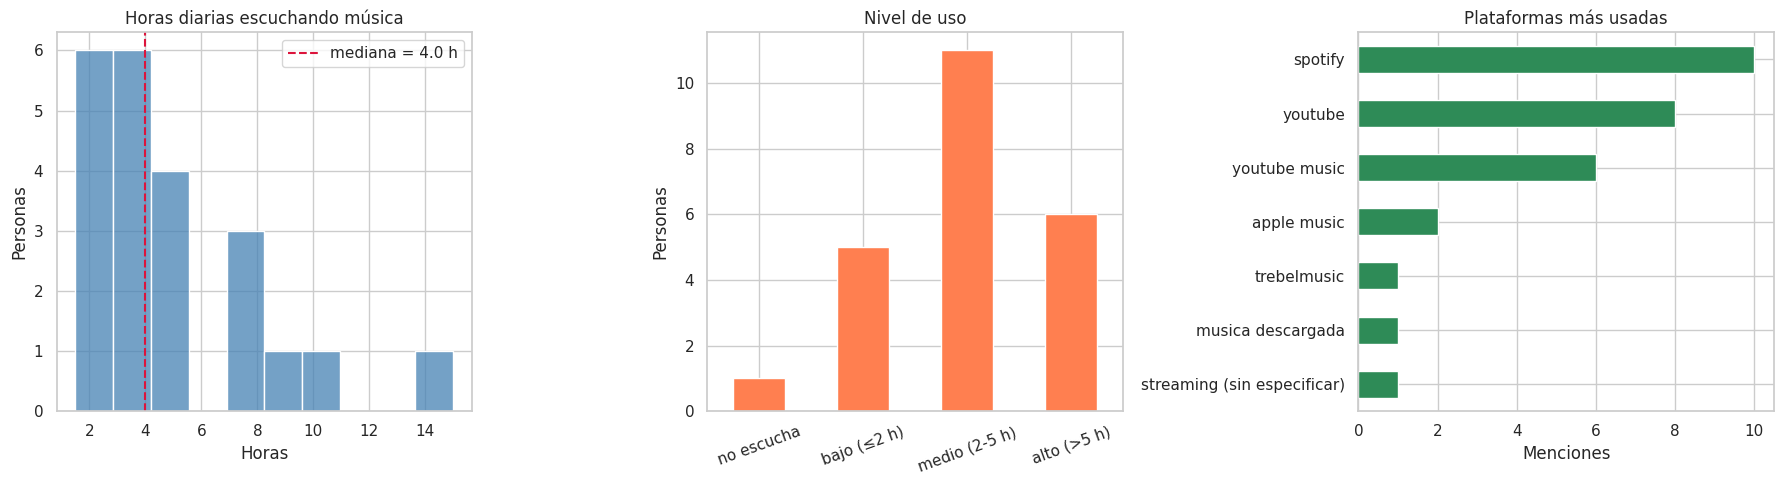

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Horas al día (solo quienes escuchan)
sns.histplot(oyentes['horas_dia'], bins=10, ax=axes[0], color='steelblue')
axes[0].axvline(oyentes['horas_dia'].median(), color='crimson', ls='--', label=f"mediana = {oyentes['horas_dia'].median():.1f} h")
axes[0].set_title('Horas diarias escuchando música'); axes[0].set_xlabel('Horas'); axes[0].set_ylabel('Personas'); axes[0].legend()

# Nivel de uso
dfa['uso_nivel'].value_counts().reindex(['no escucha', 'bajo (≤2 h)', 'medio (2-5 h)', 'alto (>5 h)']).plot(kind='bar', ax=axes[1], color='coral')
axes[1].set_title('Nivel de uso'); axes[1].set_xlabel(''); axes[1].set_ylabel('Personas'); axes[1].tick_params(axis='x', rotation=20)

# Plataformas
barras_lista(dfa['plataformas'], axes[2], 'Plataformas más usadas', color='seagreen')
plt.tight_layout(); plt.show()

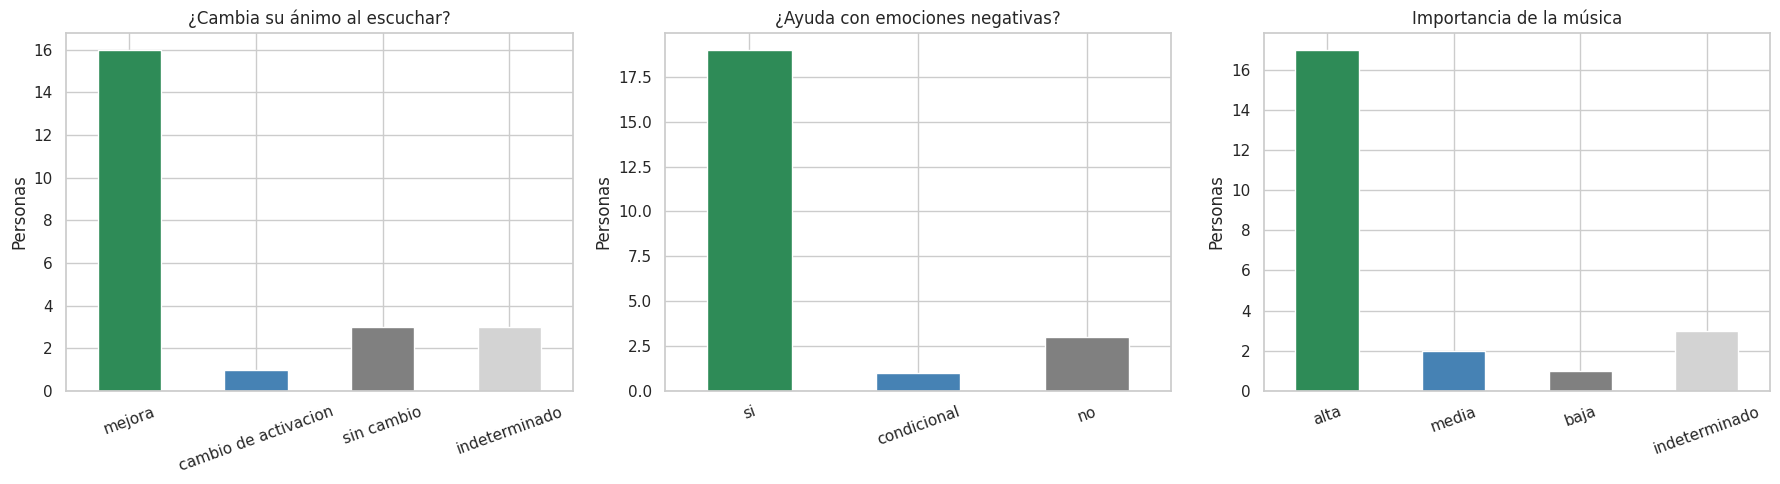

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
orden = {'cambio_animo': ['mejora', 'cambio de activacion', 'sin cambio', 'indeterminado'],
         'ayuda_emociones': ['si', 'condicional', 'no'],
         'importancia_nivel': ['alta', 'media', 'baja', 'indeterminado']}
titulos = {'cambio_animo': '¿Cambia su ánimo al escuchar?', 'ayuda_emociones': '¿Ayuda con emociones negativas?',
           'importancia_nivel': 'Importancia de la música'}
for ax, (col, ord_) in zip(axes, orden.items()):
    dfa[col].value_counts().reindex(ord_).fillna(0).plot(kind='bar', ax=ax, color=['seagreen', 'steelblue', 'gray', 'lightgray'][:len(ord_)])
    ax.set_title(titulos[col]); ax.set_xlabel(''); ax.set_ylabel('Personas'); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

## Variables significativas (top de menciones)

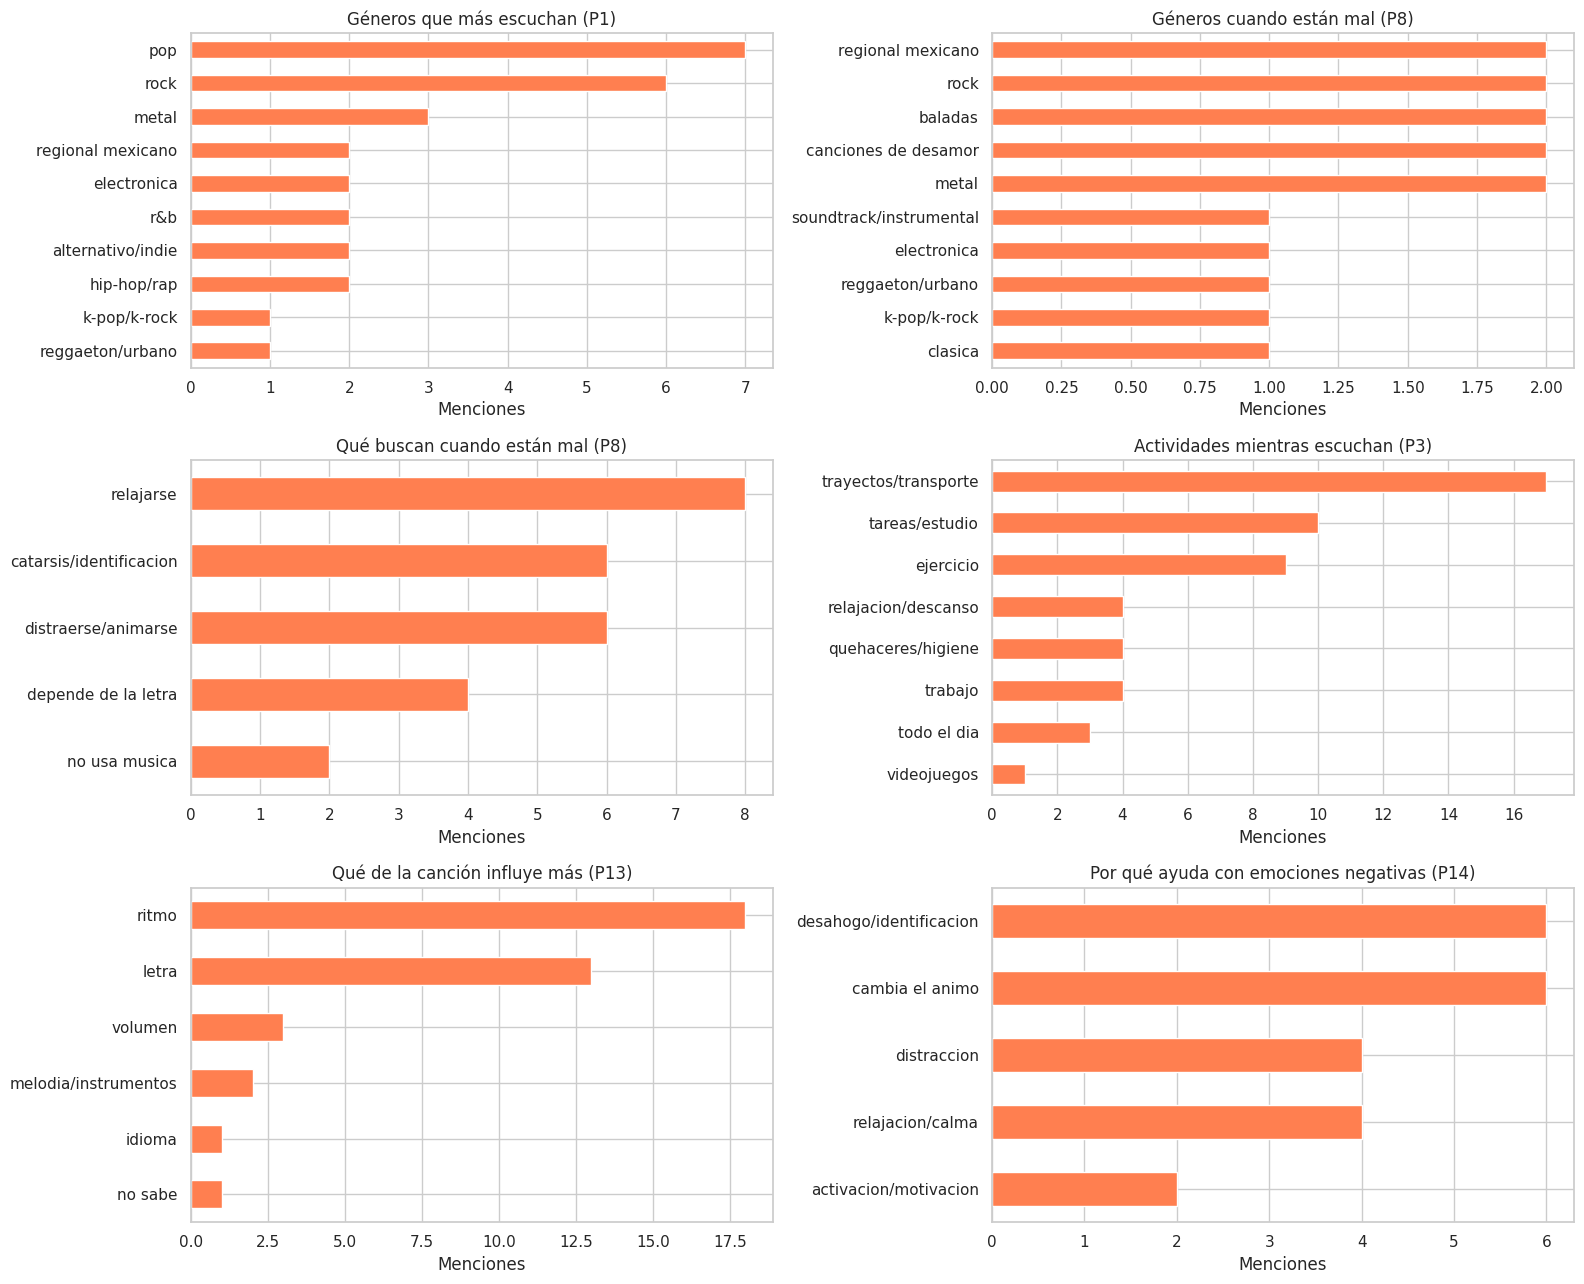

In [65]:
cols_listas = ['generos_frecuentes', 'generos_animo_negativo', 'estrategia_animo_negativo', 'actividades', 'caracteristicas_l', 'mecanismos_ayuda']
tit = ['Géneros que más escuchan (P1)', 'Géneros cuando están mal (P8)', 'Qué buscan cuando están mal (P8)',
       'Actividades mientras escuchan (P3)', 'Qué de la canción influye más (P13)', 'Por qué ayuda con emociones negativas (P14)']
fig, axes = plt.subplots(3, 2, figsize=(16, 13))
for ax, col, t in zip(axes.ravel(), cols_listas, tit):
    barras_lista(dfa[col], ax, t)
plt.tight_layout(); plt.show()

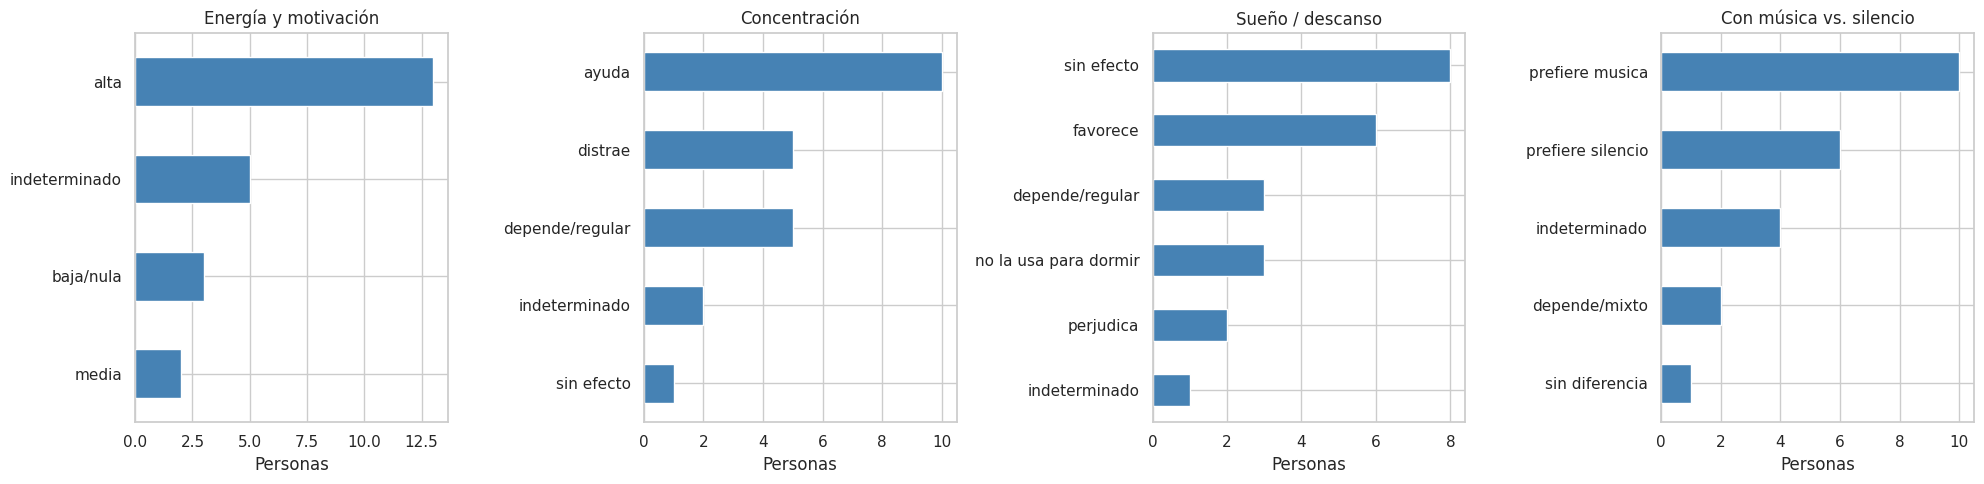

In [66]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (col, t) in zip(axes, [('influencia_energia', 'Energía y motivación'), ('efecto_concentracion', 'Concentración'),
                               ('efecto_sueno', 'Sueño / descanso'), ('prefiere', 'Con música vs. silencio')]):
    dfa[col].value_counts().sort_values().plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title(t); ax.set_xlabel('Personas'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

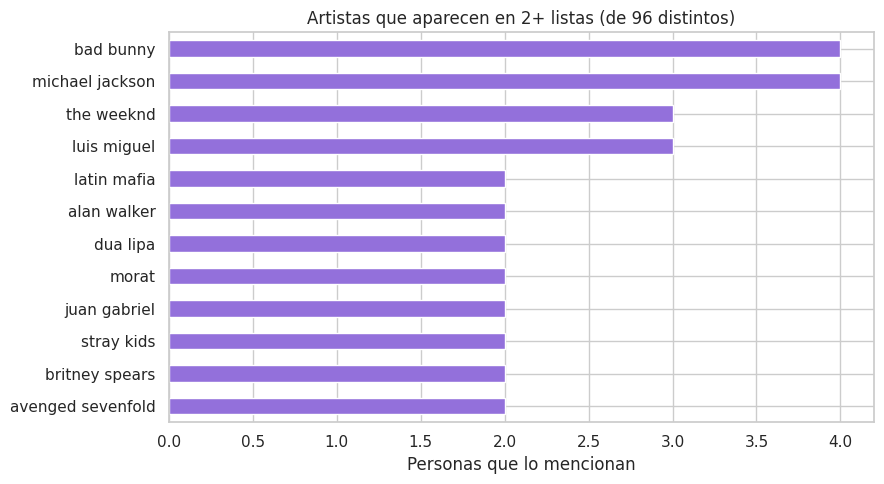

In [67]:
top = dfa['artistas'].dropna().str.split(', ').explode().value_counts()
top = top[top >= 2]
fig, ax = plt.subplots(figsize=(9, 5))
top.iloc[::-1].plot(kind='barh', ax=ax, color='mediumpurple')
ax.set_title(f'Artistas que aparecen en 2+ listas (de {dfa["artistas"].dropna().str.split(", ").explode().nunique()} distintos)')
ax.set_xlabel('Personas que lo mencionan'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

### Cruces rápidos

Con ~23 personas, estos cruces son descriptivos: sirven para formular hipótesis, no para concluir.

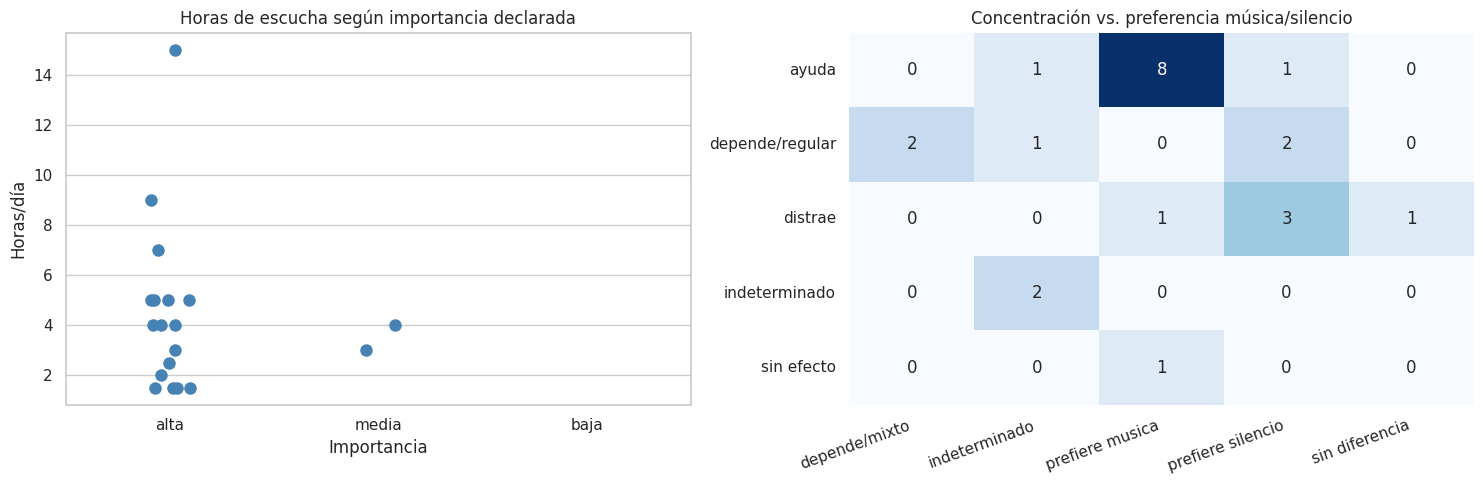

,count,median
importancia_nivel,,
alta,17,4.0
indeterminado,3,8.0
media,2,3.5


In [68]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
orden_imp = ['alta', 'media', 'baja']
sns.stripplot(data=oyentes[oyentes['importancia_nivel'].isin(orden_imp)], x='importancia_nivel', y='horas_dia',
              order=orden_imp, ax=axes[0], size=9, color='steelblue')
axes[0].set_title('Horas de escucha según importancia declarada'); axes[0].set_xlabel('Importancia'); axes[0].set_ylabel('Horas/día')

cruce = pd.crosstab(dfa['efecto_concentracion'], dfa['prefiere'])
sns.heatmap(cruce, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1])
axes[1].set_title('Concentración vs. preferencia música/silencio'); axes[1].set_xlabel(''); axes[1].set_ylabel('')
plt.setp(axes[1].get_xticklabels(), rotation=20, ha='right')
plt.tight_layout(); plt.show()

display(oyentes.groupby('importancia_nivel')['horas_dia'].agg(['count', 'median']))

## Resumen de hallazgos (calculado desde los datos)

In [69]:
n = len(dfa)
def pct(serie, valor):
    return f'{(serie == valor).sum()}/{n} ({(serie == valor).mean():.0%})'

print(f'Muestra: {n} personas ({len(oyentes)} escuchan música)')
print(f"Horas/día (mediana, quienes escuchan): {oyentes['horas_dia'].median():.1f} h · rango {oyentes['horas_dia'].min():.1f}–{oyentes['horas_dia'].max():.1f}")
print('Plataforma más usada:', dfa['plataformas'].dropna().str.split(', ').explode().value_counts().head(3).to_dict())
print('Géneros top:', dfa['generos_frecuentes'].dropna().str.split(', ').explode().value_counts().head(5).to_dict())
print('Ánimo mejora:', pct(dfa['cambio_animo'], 'mejora'), '· sin cambio:', pct(dfa['cambio_animo'], 'sin cambio'))
print('Ayuda con emociones negativas (sí):', pct(dfa['ayuda_emociones'], 'si'))
print('Energía/motivación alta:', pct(dfa['influencia_energia'], 'alta'))
print('Concentración → ayuda:', pct(dfa['efecto_concentracion'], 'ayuda'), '· distrae:', pct(dfa['efecto_concentracion'], 'distrae'),
      '· depende:', pct(dfa['efecto_concentracion'], 'depende/regular'))
print('Sueño → favorece:', pct(dfa['efecto_sueno'], 'favorece'), '· sin efecto:', pct(dfa['efecto_sueno'], 'sin efecto'),
      '· no la usa:', pct(dfa['efecto_sueno'], 'no la usa para dormir'))
print('Prefiere con música:', pct(dfa['prefiere'], 'prefiere musica'), '· silencio:', pct(dfa['prefiere'], 'prefiere silencio'))
print('Importancia alta:', pct(dfa['importancia_nivel'], 'alta'))
print('Característica clave:', dfa['caracteristicas_l'].dropna().str.split(', ').explode().value_counts().to_dict())

Muestra: 23 personas (22 escuchan música)
Horas/día (mediana, quienes escuchan): 4.0 h · rango 1.5–15.0
Plataforma más usada: {'spotify': 10, 'youtube': 8, 'youtube music': 6}
Géneros top: {'pop': 7, 'rock': 6, 'metal': 3, 'regional mexicano': 2, 'electronica': 2}
Ánimo mejora: 16/23 (70%) · sin cambio: 3/23 (13%)
Ayuda con emociones negativas (sí): 19/23 (83%)
Energía/motivación alta: 13/23 (57%)
Concentración → ayuda: 10/23 (43%) · distrae: 5/23 (22%) · depende: 5/23 (22%)
Sueño → favorece: 6/23 (26%) · sin efecto: 8/23 (35%) · no la usa: 3/23 (13%)
Prefiere con música: 10/23 (43%) · silencio: 6/23 (26%)
Importancia alta: 17/23 (74%)
Característica clave: {'ritmo': 18, 'letra': 13, 'volumen': 3, 'melodia/instrumentos': 2, 'idioma': 1, 'no sabe': 1}


### Lectura de los resultados

- **El ánimo mejora para la mayoría:** ~70 % describe un cambio positivo tras escuchar su música; solo ~13 % dice que queda igual.
- **Ayuda con emociones negativas:** ~83 % cree que sí. Los motivos más citados son *desahogo/identificación con la letra* y *cambiar el ánimo* (6 menciones cada uno), seguidos de distracción y relajación (4).
- **Ritmo y letra mandan:** el ritmo se menciona 18 veces y la letra 13; el volumen, la melodía o el idioma casi no aparecen.
- **El efecto depende del dominio:** es más claro en *energía/motivación* (~57 % alta), está dividido en *concentración* (43 % ayuda, 22 % distrae, 22 % depende; y 43 % prefiere trabajar con música frente a 26 % que prefiere silencio) y es **débil en el sueño** (la mayoría dice que no afecta o que no la usa para dormir).
- **Uso intenso pero no uniforme:** mediana de 4 h/día, con una cola larga (hasta 15 h) y Spotify/YouTube como plataformas dominantes. El pop y el rock encabezan los géneros.

**Límites a tener presentes:** son 23 personas (probablemente un solo grupo de clase), así que son porcentajes descriptivos, no estimaciones de una población. Además, la clasificación es por reglas de palabras clave: aun revisada a mano, hay respuestas ambiguas (quedan como `indeterminado`) y algunas inferencias (p. ej. "me distraigo más con música" → prefiere silencio).

## 5. Exportar datos limpios

In [70]:
columnas_finales = [
    'no_cuenta', 'posible_copia', 'n_respuestas_copiadas', 'escucha_musica',
    'horas_dia', 'horas_o_mas', 'horas_atipico', 'uso_nivel',
    'plataformas', 'n_plataformas'] + [c for c in df.columns if c.startswith('usa_')] + [
    'generos_frecuentes', 'razon_genero', 'generos_emocion', 'generos_animo_negativo', 'estrategia_animo_negativo',
    'actividades', 'momentos_dia', 'cambio_animo', 'experiencia_cambio', 'tuvo_experiencia', 'experiencia_conceptos',
    'influencia_energia', 'efecto_concentracion', 'efecto_sueno', 'prefiere',
    'caracteristicas_l', 'ayuda_emociones', 'mecanismos_ayuda', 'importancia_nivel', 'artistas', 'n_artistas',
]
limpio = df[columnas_finales].rename(columns={'caracteristicas_l': 'caracteristicas'})
PROCESSED_CSV.parent.mkdir(parents=True, exist_ok=True)
limpio.to_csv(PROCESSED_CSV, index=False, encoding='utf-8-sig')
print(f"✓ Datos limpios guardados en: {PROCESSED_CSV}")
print(f"  Filas: {len(limpio)}")
print(f"  Columnas: {len(limpio.columns)}")

✓ Datos limpios guardados en: data/processed/datos_limpios_musica.csv
  Filas: 24
  Columnas: 38


In [71]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
